In [2]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple
from bayesian_network import BayesNet
from math import lgamma
from utils import sample_forward, get_default_bayes_net, draw_graph

np.set_printoptions(precision=3, suppress=True)

### BayesNet Class
<div class="alert alert-danger">

**Read the `BayesNet_class_description.ipynb` notebook** before you start working on this problem set! It contains a detailed description of the provided classes *BayesNet* and *Variable*.

</div>

We use the same `BayesNet` and `utils.py` implementations as in the previous parameter-learning assignment. In this notebook, the **network structure is known**; we only learn its conditional probability distributions.

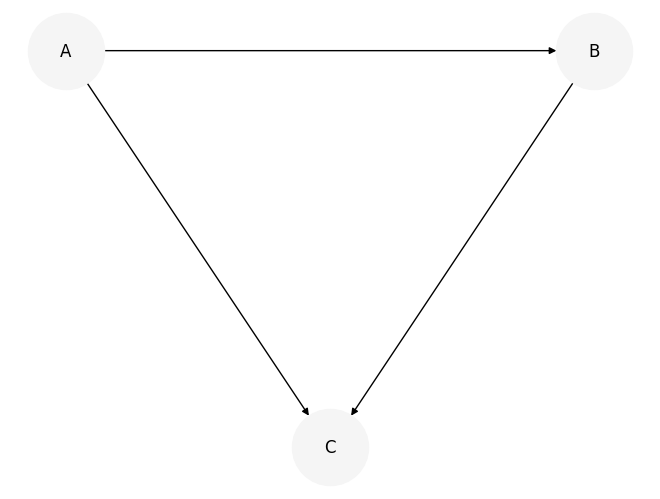

In [3]:
_A_, _B_, _C_ = 0, 1, 2
pdts = [
    (np.ones((2,)) * 0.5, (_A_,)),
    (np.ones((2, 2)) * 0.5, (_B_, _A_)),
    (np.ones((2, 2, 2)) * 0.5, (_C_, _A_, _B_)),
]
bn = BayesNet(*pdts)
draw_graph(bn, node_names=['A', 'B', 'C'],
           pos={'A': [0., 1.], 'B': [1., 1.], 'C': [.5, .5]})

---
# Bayesian Parameter Learning

We assume a fixed dependency graph structure and learn the parameters (complete Conditional Probability Distribution Tables, **CPDTs**) from fully observed events. In contrast to maximum-likelihood estimation, Bayesian parameter estimation treats the parameters as uncertain and starts from a prior distribution.

All variables in this assignment are **binary** (value 0 or 1). For each conditional probability $\theta_u=P(X=1\mid u)$ we use an independent Beta prior:

$$\theta_u \sim \operatorname{Beta}(\alpha,\beta).$$

If $N[1,u]$ and $N[0,u]$ are the counts of the two outcomes for a particular parent configuration $u$, then

$$p(\theta_u\mid D)=\operatorname{Beta}(\alpha+N[1,u],\;\beta+N[0,u]).$$

**Your tasks:** Implement only the **posterior mean** and the **posterior mode / MAP**. Constructing the Bayesian networks, plotting, and evaluation are provided.

The resulting CPDTs must follow the same conventions as in the previous notebook: axis 0 corresponds to the variable itself, and the remaining axes follow `parent_ids`.

## 1. Posterior Mean Estimation (3 points)

<div class="alert alert-warning">
    Implement the <i>posterior_mean_estimate</i> function, which computes the posterior mean of each conditional Bernoulli parameter given a Beta prior and a data set.
</div>

The function takes:
- `data`: a NumPy array of shape `(num_samples, num_variables)` containing binary observations;
- `variable_id`: the column index of the variable;
- `parent_ids`: a tuple containing the column indices of its parents;
- `alpha`, `beta`: the positive parameters of the Beta prior (the same prior for each parent configuration).

For each parent configuration $u$, calculate

$$\hat\theta_{\mathrm{mean},u}=\frac{N[1,u]+\alpha}{N[1,u]+N[0,u]+\alpha+\beta}.$$

The function must return an `np.ndarray` representing $P(X\mid u)$: the first entry for each parent configuration is $P(X=0\mid u)$, the second is $P(X=1\mid u)$. Return an array with shape `(2,) + (2,) * len(parent_ids)`.

In [4]:
# Count the two outcomes separately for each parent configuration
def _binary_counts(data: np.ndarray, variable_id: int, parent_ids: tuple) -> np.ndarray:

    # Reserve one binary axis for the target followed by one for each parent
    shape = (2,) + (2,) * len(parent_ids)

    # Start all counts at zero including configurations absent from the data
    counts = np.zeros(shape, dtype=int)

    # Select the target and parent columns in the same order as the axes
    assignments = data[:, (variable_id,) + parent_ids].astype(np.intp, copy=False)

    # Add one per observation including repeated assignments
    np.add.at(counts, tuple(assignments.T), 1)

    # Return the counts for outcomes zero and one on axis zero
    return counts


# Estimate each conditional probability from the mean of its Beta posterior
def posterior_mean_estimate(data: np.ndarray, variable_id: int, parent_ids: tuple=tuple(),
                            alpha: float=1.0, beta: float=1.0) -> np.ndarray:
    """Estimate a binary CPDT by the posterior mean under independent Beta priors."""
    # Require positive shape parameters for the Beta prior
    assert alpha > 0 and beta > 0

    # Count zeros and ones for each parent configuration
    n_zero, n_one = _binary_counts(data, variable_id, parent_ids)

    # Add the observed ones to the first shape parameter
    posterior_alpha = alpha + n_one

    # Add the observed zeros to the second shape parameter
    posterior_beta = beta + n_zero

    # Divide the first posterior shape by the sum of both shapes
    p_one = posterior_alpha / (posterior_alpha + posterior_beta)

    # Stack the complementary probability and the probability of one on axis zero
    cpdt = np.stack((1 - p_one, p_one), axis=0)
    return cpdt

In [5]:
# Example: 3 successes and 2 failures for a variable without parents.
toy_data = np.array([[1], [0], [1], [0], [1]], dtype=int)

# Sanity checks for Task 1
actual = posterior_mean_estimate(toy_data, 0, alpha=1, beta=1)
assert np.allclose(actual, [3/7, 4/7])
assert np.allclose(actual.sum(axis=0), 1)

conditional_data = np.array([[0,0], [0,0], [1,0], [1,1]], dtype=int)
actual = posterior_mean_estimate(conditional_data, 0, parent_ids=(1,), alpha=2, beta=2)
assert actual.shape == (2,2)
assert np.allclose(actual[1], [3/7, 3/5])
assert np.allclose(actual.sum(axis=0), 1)

# A parent configuration not observed in the data must fall back to the prior mean.
assert np.isclose(posterior_mean_estimate(np.array([[0,0]]), 0, (1,), alpha=2, beta=3)[1,1], 2/5)

## 2. Posterior Mode Estimation (MAP) (1 points)

<div class="alert alert-warning">
    Implement the <i>posterior_mode_estimate</i> function, which computes the posterior mode (Maximum A Posteriori, MAP) of each conditional Bernoulli parameter given a Beta prior and a data set.
</div>

For the posterior $\operatorname{Beta}(\alpha+N[1,u],\;\beta+N[0,u])$, the mode is

$$\hat\theta_{\mathrm{MAP},u}=\frac{N[1,u]+\alpha-1}{N[1,u]+N[0,u]+\alpha+\beta-2}.$$

**Assumption for this task:** `alpha > 1` and `beta > 1`. This ensures that the posterior mode is uniquely defined and in the interior, even when a parent configuration has no observations. The uniform prior `Beta(1,1)` will be discussed separately in the demonstration.

The arguments and return format are the same as for Task 1. **Hint:** Compute $P(X=1\mid u)$, then stack its complement and itself along axis 0.

In [6]:
# Estimate each conditional probability from the mode of its Beta posterior
def posterior_mode_estimate(data: np.ndarray, variable_id: int, parent_ids: tuple=tuple(),
                            alpha: float=2.0, beta: float=2.0) -> np.ndarray:
    """Estimate a binary CPDT by the posterior mode under independent Beta priors."""
    # Require both prior shapes to exceed one for a unique interior mode
    assert alpha > 1 and beta > 1, 'This task assumes alpha > 1 and beta > 1.'

    # Count zeros and ones for each parent configuration
    n_zero, n_one = _binary_counts(data, variable_id, parent_ids)

    # Subtract one from the first posterior shape for the mode formula
    mode_alpha = (alpha - 1) + n_one

    # Subtract one from the second posterior shape for the mode formula
    mode_beta = (beta - 1) + n_zero

    # Divide the adjusted first shape by the sum of both adjusted shapes
    p_one = mode_alpha / (mode_alpha + mode_beta)

    # Stack the complementary probability and the probability of one on axis zero
    cpdt = np.stack((1 - p_one, p_one), axis=0)
    return cpdt

In [7]:
# Example: 3 successes and 2 failures for a variable without parents.
toy_data = np.array([[1], [0], [1], [0], [1]], dtype=int)

# Sanity checks for Task 2
actual = posterior_mode_estimate(toy_data, 0, alpha=2, beta=2)
assert np.allclose(actual, [3/7, 4/7])  # MAP with Beta(2,2): 4/7
assert np.allclose(actual.sum(axis=0), 1)

actual = posterior_mode_estimate(conditional_data, 0, parent_ids=(1,), alpha=2, beta=2)
assert actual.shape == (2,2)
assert np.allclose(actual[1], [2/5, 2/3])
assert np.allclose(actual.sum(axis=0), 1)

assert np.isclose(posterior_mode_estimate(np.array([[0,0]]), 0, (1,), alpha=2, beta=3)[1,1], 1/3)

---
# Demonstration: Posterior Mean vs. Posterior Mode

Everything below is provided. There are no additional implementation tasks. Run the cells and inspect the results.

The demonstration connects the Bayesian estimators to maximum-likelihood estimation and Laplace correction, visualizes the effect of different priors, and finally applies both estimators to the stroke Bayesian network.

### A. Uninformed prior, maximum likelihood and Laplace correction

For $N>0$ Bernoulli observations, under $\operatorname{Beta}(1,1)$ the posterior mean is $(k+1)/(N+2)$, which is the **Laplace-smoothed estimate**. The posterior mode is $k/N$, which coincides with **MLE** (including its boundary cases).

If there are **no observations**, the posterior remains uniform and **there is no unique mode**; in particular, applying the MAP formula would give $0/0$.

The following display uses $N=2$ trials with no successes.

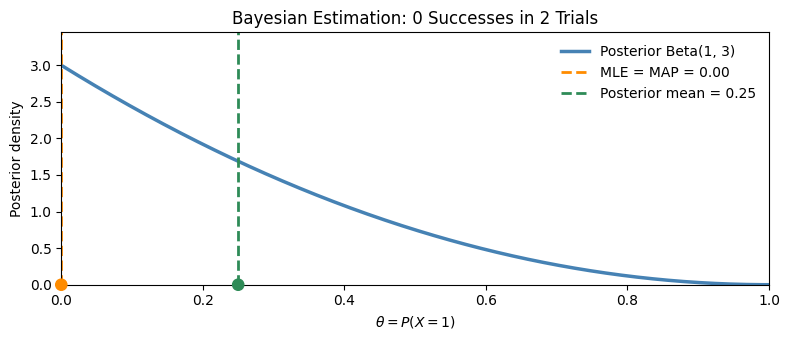

In [8]:
# The two observed failures form a small binary dataset.
demo_data = np.array([[0], [0]], dtype=int)
n = len(demo_data)
k = int(np.sum(demo_data[:, 0]))
theta = np.linspace(0, 1, 500)
post_a, post_b = k + 1, n - k + 1

# With Beta(1,1), MAP = MLE for N > 0. The provided MAP function
# deliberately assumes alpha,beta > 1, so this boundary case uses MLE.
mle = np.mean(demo_data[:, 0])
uniform_map = mle
uniform_mean = posterior_mean_estimate(demo_data, 0, alpha=1, beta=1)[1]

def beta_pdf(x, a, b):
    log_norm = lgamma(a + b) - lgamma(a) - lgamma(b)
    x = np.clip(x, 1e-12, 1 - 1e-12)
    return np.exp(log_norm + (a - 1) * np.log(x) + (b - 1) * np.log(1 - x))

density = beta_pdf(theta, post_a, post_b)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(theta, density, color='steelblue', lw=2.5,
        label=f'Posterior Beta({post_a}, {post_b})')
ax.axvline(uniform_map, color='darkorange', ls='--', lw=2,
           label=f'MLE = MAP = {mle:.2f}')
ax.axvline(uniform_mean, color='seagreen', ls='--', lw=2,
           label=f'Posterior mean = {uniform_mean:.2f}')
ax.scatter([uniform_map, uniform_mean], [0, 0],
           c=['darkorange', 'seagreen'], s=65, zorder=5, clip_on=False)
ax.set(title='Bayesian Estimation: 0 Successes in 2 Trials',
       xlabel=r'$\theta = P(X=1)$', ylabel='Posterior density',
       xlim=(0, 1), ylim=(0, max(density) * 1.15))
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### B. The effect of different priors

We keep the same two observations ($N=2$, $k=0$), but change the prior: `Beta(1,1)`, `Beta(1.1,1.1)`, and `Beta(2,2)`. Compare the **location** of the posterior mode with the **average** of the posterior distribution. Notice how both estimates can be quite different with very little data.

The code uses the analytical Beta density for visualization only. No implementation is required.

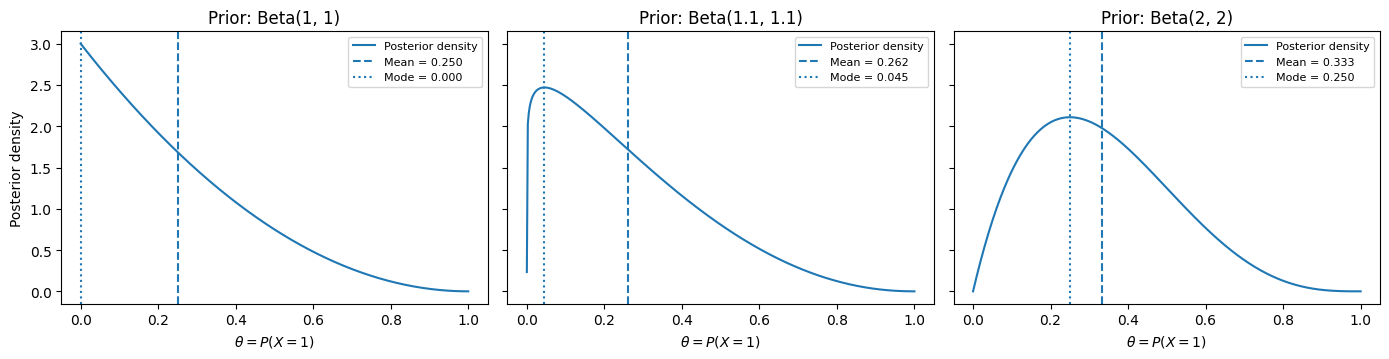

In [9]:
# The two observed failures form a small binary dataset.
demo_data = np.array([[0], [0]], dtype=int)
n = len(demo_data)
k = int(np.sum(demo_data[:, 0]))

priors = [(1.0, 1.0), (1.1, 1.1), (2.0, 2.0)]
fig, axes = plt.subplots(1, len(priors), figsize=(14, 3.7), sharey=True)
theta = np.linspace(0, 1, 400)

for ax, (alpha, beta) in zip(axes, priors):
    post_a, post_b = alpha + k, beta + n - k
    mean = posterior_mean_estimate(demo_data, 0, alpha=alpha, beta=beta)[1]
    if alpha == beta == 1.0:
        mode = np.mean(demo_data[:, 0])
    else:
        mode = posterior_mode_estimate(demo_data, 0, alpha=alpha, beta=beta)[1]

    ax.plot(theta, beta_pdf(theta, post_a, post_b), label='Posterior density')
    ax.axvline(mean, linestyle='--', label=f'Mean = {mean:.3f}')
    ax.axvline(mode, linestyle=':', label=f'Mode = {mode:.3f}')
    ax.set_title(f'Prior: Beta({alpha:g}, {beta:g})')
    ax.set_xlabel(r'$\theta = P(X=1)$')
    ax.legend(fontsize=8)

axes[0].set_ylabel('Posterior density')
plt.tight_layout()
plt.show()

### C. Application to the stroke Bayesian network

We use the Bayesian network from the previous notebook with five binary variables: alcohol consumption ($A$), high blood pressure ($H$), stroke ($S$), confusion ($C$), and vertigo ($V$).

The joint distribution factorizes as

$$
P(A,H,S,C,V)=P(A)P(H\mid A)P(S\mid H)P(C\mid A,S)P(V\mid S).
$$

We investigate how **training set size** and **prior strength** affect the quality of three estimators: maximum likelihood (MLE), posterior mean, and posterior mode (MAP).

#### Define the Bayesian network

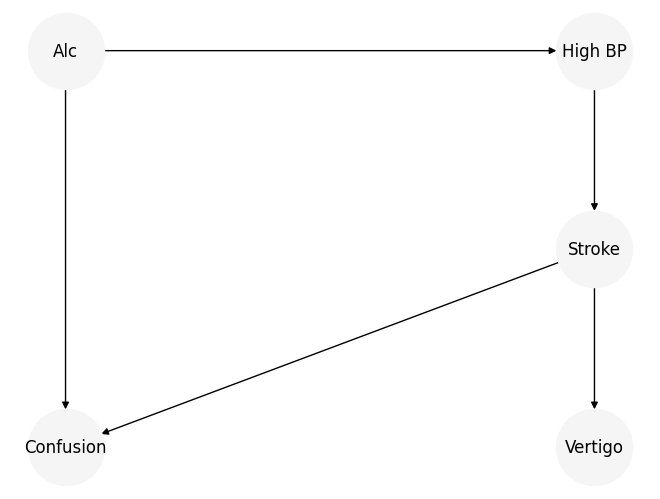

In [10]:
_A_, _H_, _S_, _C_, _V_ = 0, 1, 2, 3, 4

A = np.array([0.01, 0.99])
H_A = np.array([[0.9, 0.8], [0.1, 0.2]])
S_H = np.array([[0.9, 0.85], [0.1, 0.15]])
C_AS = np.array([[[0.8, 0.7], [0.85, 0.45]],
                 [[0.2, 0.3], [0.15, 0.55]]])
V_S = np.array([[0.1, 0.2], [0.9, 0.8]])

true_bayes_net = BayesNet(
    (A, (_A_,)),
    (H_A, (_H_, _A_)),
    (S_H, (_S_, _H_)),
    (C_AS, (_C_, _A_, _S_)),
    (V_S, (_V_, _S_))
)

draw_graph(
    true_bayes_net,
    node_names=['Alc', 'High BP', 'Stroke', 'Confusion', 'Vertigo'],
    pos={'Alc': [0., 2.], 'High BP': [1.5, 2.],
         'Stroke': [1.5, 1.], 'Confusion': [0., 0.],
         'Vertigo': [1.5, 0.]}
)

#### Compare estimators across dataset sizes

We focus on the conditional probability

$$
P(C=1\mid A=0,S=0)=0.2.
$$

Since this parent configuration is relatively rare, estimates can be unstable for small datasets.

We compare three Beta priors with increasing regularization strength:
- $\mathrm{Beta}(1,1)$,
- $\mathrm{Beta}(1.1,1.1)$, and
- $\mathrm{Beta}(10,10)$.

To evaluate estimation quality, we calculate the **KL divergence** between the true and estimated Bernoulli distributions and average it over multiple independently generated datasets. Lower KL divergence indicates a better estimate.

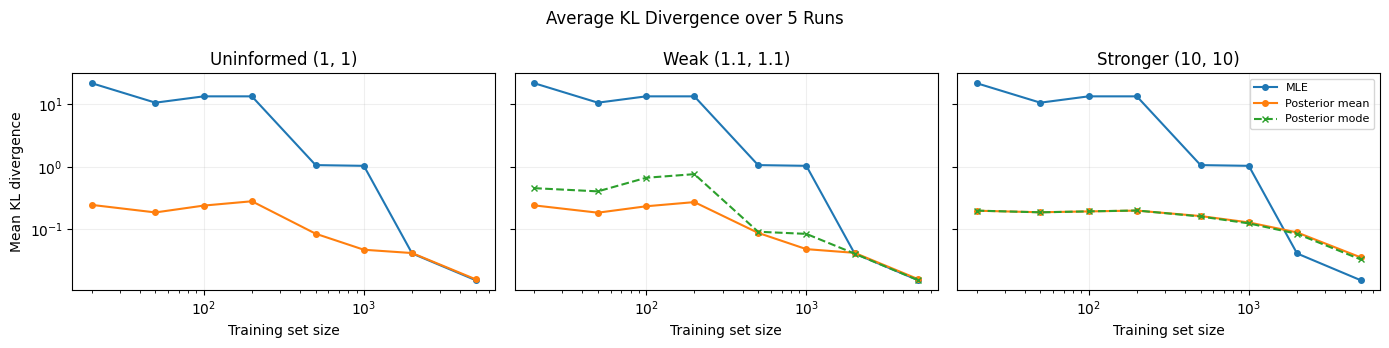

In [11]:
sizes = [20, 50, 100, 200, 500, 1000, 2000, 5000]
n_runs = 5

priors = {
    'Uninformed (1, 1)': (1.0, 1.0),
    'Weak (1.1, 1.1)': (1.1, 1.1),
    'Stronger (10, 10)': (10.0, 10.0)
}

true_p = C_AS[1, 0, 0]

def kl_bernoulli(p, q):
    q = np.clip(q, 1e-12, 1 - 1e-12)
    return p * np.log(p / q) + (1 - p) * np.log((1 - p) / (1 - q))

results = {
    label: {name: np.full((n_runs, len(sizes)), np.nan)
            for name in ['MLE', 'Posterior mean', 'Posterior mode']}
    for label in priors
}

np.random.seed(42)


for run in range(n_runs):
    data = sample_forward(true_bayes_net, max(sizes))

    for i, n in enumerate(sizes):
        subset = data[:n]

        n_total = np.sum((subset[:, _A_] == 0) & (subset[:, _S_] == 0))
        n_ones = np.sum(
            (subset[:, _A_] == 0) &
            (subset[:, _S_] == 0) &
            (subset[:, _C_] == 1)
        )
        mle = n_ones / n_total if n_total > 0 else np.nan

        for label, (alpha, beta) in priors.items():
            mean = posterior_mean_estimate(
                subset, _C_, (_A_, _S_), alpha=alpha, beta=beta
            )[1, 0, 0]

            if alpha == beta == 1.0:
                mode = mle
            else:
                mode = posterior_mode_estimate(
                    subset, _C_, (_A_, _S_), alpha=alpha, beta=beta
                )[1, 0, 0]

            estimates = {
                'MLE': mle,
                'Posterior mean': mean,
                'Posterior mode': mode
            }

            for name, q in estimates.items():
                if np.isfinite(q):
                    results[label][name][run, i] = kl_bernoulli(true_p, q)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)

for ax, (label, estimates) in zip(axes, results.items()):
    for name, values in estimates.items():
        # For Beta(1,1), MAP and MLE are identical whenever defined.
        # Draw a single line so neither curve hides the other.
        if label == 'Uninformed (1, 1)' and name == 'Posterior mode':
            continue
        avg_kl = np.nanmean(values, axis=0)
        display_name = ('MLE = Posterior mode'
                        if label == 'Uninformed (1, 1)' and name == 'MLE'
                        else name)
        ax.plot(sizes, avg_kl, 'x--' if name == 'Posterior mode' else 'o-',
                ms=4, label=display_name)

    ax.set(title=label, xlabel='Training set size')
    ax.set_xscale('log')
    ax.set_yscale('symlog', linthresh=1e-3)
    ax.grid(alpha=0.2)

axes[0].set_ylabel('Mean KL divergence')
axes[-1].legend(fontsize=8)
plt.suptitle(f'Average KL Divergence over {n_runs} Runs')
plt.tight_layout()
plt.show()

With small datasets, the **MLE can produce extreme estimates**, while the posterior mean provides smoothing through the prior. Under a uninformative prior, the MAP estimate coincides with the MLE whenever relevant observations are available. In the leftmost plot, the line corresponding to the MAP estimate is hidden behind the MLE estimate.

Stronger priors pull estimates toward $0.5$. Since the true probability is $0.2$, this can introduce additional bias. As the number of relevant observations increases, the influence of the prior decreases and the estimators generally converge.